# Exemple : niveau de la Romanche

À lancer depuis le dossier `niveau_eau/` (là où se trouve `niveau_eau.py`).

1. **Récupérer les photos** de la caméra avec l'API du site.
2. **Mesurer le niveau** sur la dernière photo avec `mesurer_niveau`.
3. **Les 3 modèles sur les 5 derniers jours** : le graphe de la page d'accueil du projet.

## 1. Récupérer les photos avec l'API

`/api/captures` donne la liste des photos (100 par page, de la plus récente à la plus ancienne), `/img/...` donne la photo elle-même. Une photo toutes les 30 min, de jour.

109 photos sur les 5 derniers jours, la dernière du 27/11 à 16:30 (Paris)


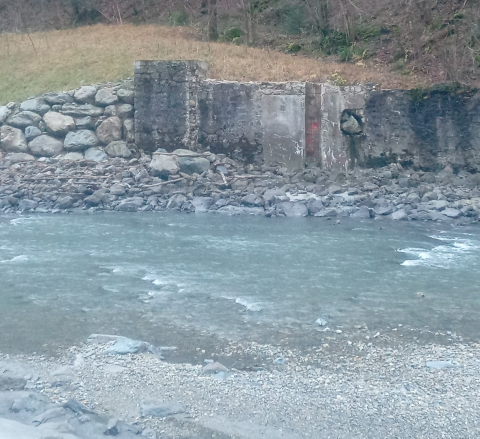

In [1]:
import io
import json
import urllib.request
from datetime import datetime, timedelta, timezone
from zoneinfo import ZoneInfo

from PIL import Image

API = "https://romanche.simon-duchene.workers.dev"
PARIS = ZoneInfo("Europe/Paris")


def lire(chemin):
    requete = urllib.request.Request(API + chemin, headers={"User-Agent": "exemple-niveau-eau"})
    with urllib.request.urlopen(requete, timeout=60) as r:
        return r.read()


def photos_depuis(debut):
    """Photos publiées depuis `debut`, de la plus récente à la plus ancienne : [{"prise", "img"}, ...]."""
    photos, avant = [], None
    while True:
        page = json.loads(lire("/api/captures?limit=100" + (f"&before={avant}" if avant else "")))
        for item in page["items"]:
            prise = datetime.fromisoformat(item["captured_at"].replace("Z", "+00:00"))
            if prise < debut:
                return photos
            photos.append({"prise": prise, "img": item["img"]})
        avant = page.get("next_before")
        if not avant:
            return photos


def telecharger(photo):
    return Image.open(io.BytesIO(lire(photo["img"])))


maintenant = datetime.now(timezone.utc)
photos = photos_depuis(maintenant - timedelta(days=5))
print(f"{len(photos)} photos sur les 5 derniers jours, la dernière du "
      f"{photos[0]['prise'].astimezone(PARIS):%d/%m à %H:%M} (Paris)")
telecharger(photos[0]).reduce(4)

## 2. Mesurer le niveau sur une photo

`mesurer_niveau(image, methode)` prend la photo telle quelle (chemin, image PIL ou tableau numpy). Méthode 1 = SAM sans entraînement, 2 = SAM affiné, 3 = DINOv2 (par défaut). Les poids (250 Mo) se téléchargent au premier appel. Une photo de nuit donne `nan`.

27/11 16:30 : niveau 858 px, hauteur 0.93 m


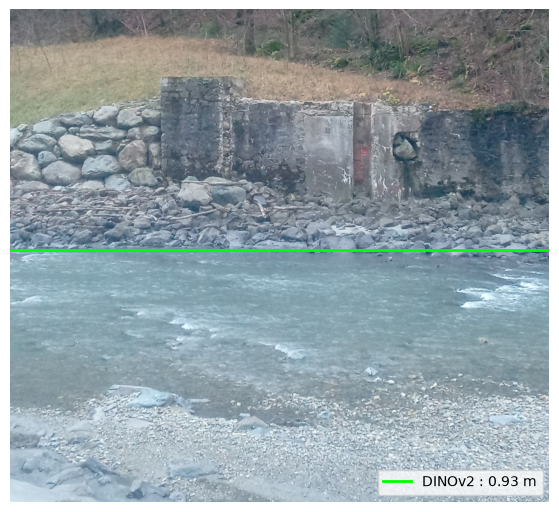

In [2]:
import matplotlib.pyplot as plt

from niveau_eau import METHODES, mesurer_niveau, trop_sombre

# dernière photo de jour
photo_api = next(p for p in photos if not trop_sombre(telecharger(p)))
photo = telecharger(photo_api)

niveau_px = mesurer_niveau(photo, methode=3)                  # pixels depuis le haut de l'image
hauteur_m = mesurer_niveau(photo, methode=3, en_metres=True)  # mètres
print(f"{photo_api['prise'].astimezone(PARIS):%d/%m %H:%M} : niveau {niveau_px:.0f} px, hauteur {hauteur_m:.2f} m")

plt.figure(figsize=(7, 6.4))
plt.imshow(photo)
plt.axhline(niveau_px, color="lime", lw=2, label=f"DINOv2 : {hauteur_m:.2f} m")
plt.legend(loc="lower right")
plt.axis("off");

## 3. Les 3 modèles sur les 5 derniers jours

Toutes les photos des 5 derniers jours, mesurées par les 3 modèles (quelques minutes ; les photos de nuit sont ignorées).

In [3]:
import pandas as pd

MODELES = [(3, "DINOv2", (40, 220, 90)), (2, "SAM affiné", (40, 140, 255)), (1, "SAM brut", (255, 50, 50))]

lignes = []
for i, p in enumerate(reversed(photos)):                     # de la plus ancienne à la plus récente
    image = telecharger(p)
    ligne = {"prise": p["prise"].astimezone(PARIS).replace(tzinfo=None)}
    for methode, nom, _ in MODELES:
        ligne[nom] = mesurer_niveau(image, methode=methode, en_metres=True)
    lignes.append(ligne)
    if i % 20 == 0:
        print(f"{i + 1}/{len(photos)}", flush=True)
mesures = pd.DataFrame(lignes).set_index("prise")
mesures.dropna().tail()

1/109


Loading weights:   0%|          | 0/357 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/357 [00:00<?, ?it/s]

21/109


41/109


61/109


81/109


101/109


,DINOv2,SAM affiné,SAM brut
prise,,,
2026-11-27 14:30:10.880477,0.93,0.91,0.80
2026-11-27 15:00:04.975927,0.94,0.92,0.83
2026-11-27 15:30:11.083499,0.92,0.91,0.81
2026-11-27 16:00:11.175895,0.93,0.92,0.84
2026-11-27 16:30:06.303141,0.93,0.91,0.85


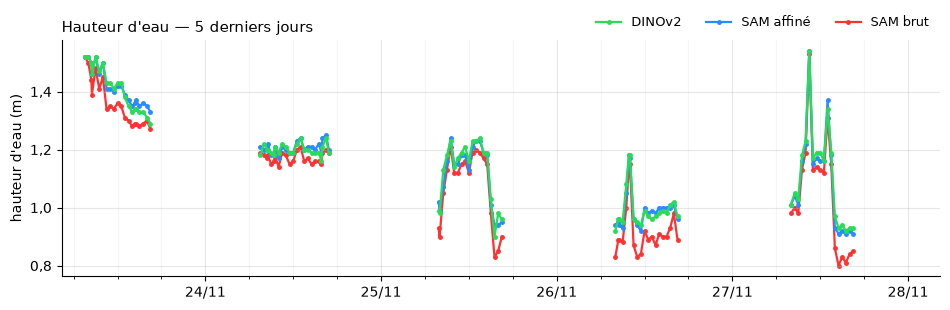

In [4]:
import matplotlib
import matplotlib.dates as mdates

points = mesures.dropna()
# trou de plus de 2 h (la nuit) : on coupe le trait
nuits = points.index.to_series().diff() > pd.Timedelta(hours=2)
coupes = pd.DataFrame(index=points.index[nuits] - pd.Timedelta(minutes=1), columns=points.columns, dtype=float)
points = pd.concat([points, coupes]).sort_index()

fig, ax = plt.subplots(figsize=(9.6, 3.2), dpi=100)
for i, (_, nom, couleur) in reversed(list(enumerate(MODELES))):
    ax.plot(points.index, points[nom], "-o", ms=2.5, lw=1.6, color=[c / 255 for c in couleur],
            label=nom, zorder=3 - i)
ax.set_xlim((maintenant - timedelta(days=5)).astimezone(PARIS).replace(tzinfo=None),
            maintenant.astimezone(PARIS).replace(tzinfo=None))
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.set_ylabel("hauteur d'eau (m)")
ax.set_title("Hauteur d'eau — 5 derniers jours", fontsize=11, loc="left")
ax.grid(alpha=0.3)
ax.grid(alpha=0.12, which="minor", axis="x")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower right", bbox_to_anchor=(1, 1), ncol=3, fontsize=9,
          frameon=False)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)
fig.tight_layout()